# Lab 5 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab05.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.


In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import matplotlib.pyplot as plt
import torch
import lab05

NPZ = '../data/parts_shapes.npz'
X, y = lab05.load_data(NPZ)
CLASSES = [str(c) for c in np.load(NPZ, allow_pickle=False)['classes']]
results = lab05.run_experiment(X, y)
results

{'baseline': {'accuracy': 0.2573, 'trainable_params': 0},
 'scratch': {'accuracy': 0.8229, 'trainable_params': 7940},
 'transfer': {'accuracy': 0.9469, 'trainable_params': 2052}}

## Plot 1 — What the images look like

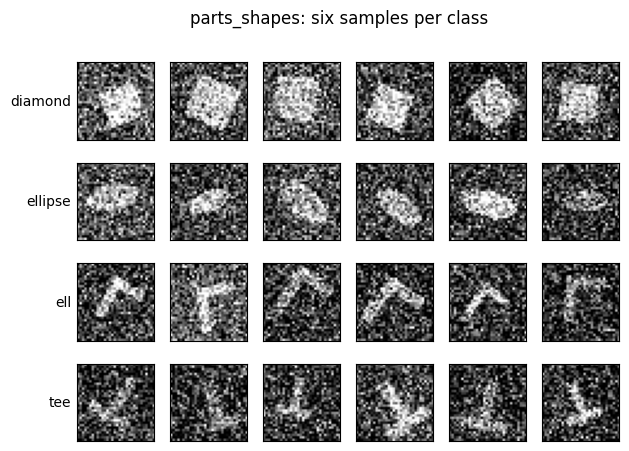

In [2]:
fig, axes = plt.subplots(4, 6, figsize=(7, 5))
for c in range(4):
    idx = torch.nonzero(y == c).ravel()[:6]
    for j in range(6):
        ax = axes[c, j]
        ax.imshow(X[idx[j], 0], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
    axes[c, 0].set_ylabel(CLASSES[c], rotation=0, ha='right', va='center')
fig.suptitle('parts_shapes: six samples per class')
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 2 — How the gap depends on the number of labels

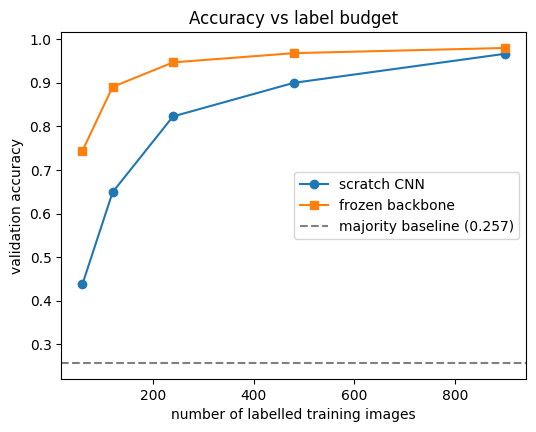

In [3]:
budgets = [60, 120, 240, 480, 900]
scratch_acc = []
transfer_acc = []

for n in budgets:
    X_tr, X_val, y_tr, y_val = lab05.split_data(X, y, n_train=n)

    lab05.set_seed()
    m = lab05.build_cnn(lab05.N_CLASSES)
    lab05.train_model(m, X_tr, y_tr)
    scratch_acc.append(lab05.accuracy(y_val, lab05.predict(m, X_val)))

    lab05.set_seed()
    m = lab05.build_transfer_model(lab05.N_CLASSES, lab05.WEIGHTS_PATH)
    lab05.train_model(m, X_tr, y_tr)
    transfer_acc.append(lab05.accuracy(y_val, lab05.predict(m, X_val)))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(budgets, scratch_acc, marker='o', label='scratch CNN')
ax.plot(budgets, transfer_acc, marker='s', label='frozen backbone')
ax.axhline(results['baseline']['accuracy'], linestyle='--', color='gray',
           label=f"majority baseline ({results['baseline']['accuracy']:.3f})")
ax.set_xlabel('number of labelled training images')
ax.set_ylabel('validation accuracy')
ax.set_title('Accuracy vs label budget')
ax.legend()
plt.savefig('fig2.png', dpi=150, bbox_inches='tight')
plt.show()

## Plot 3 — Which classes get confused

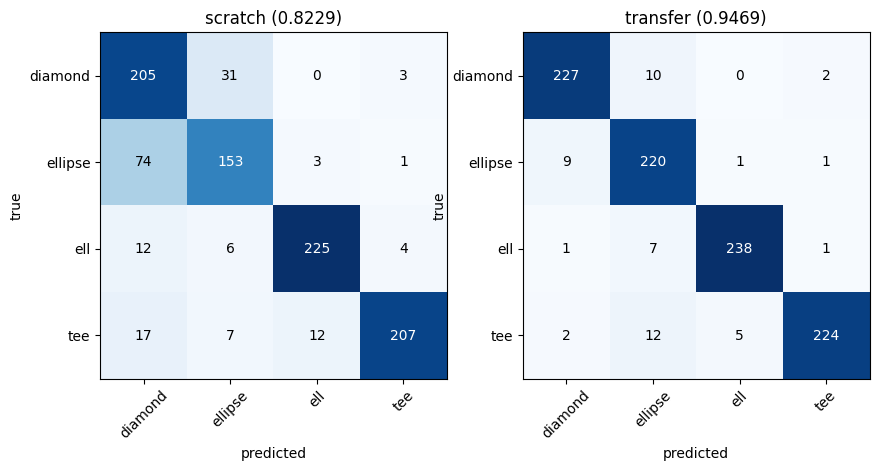

In [4]:
X_tr, X_val, y_tr, y_val = lab05.split_data(X, y)

preds = {}
lab05.set_seed()
m = lab05.build_cnn(lab05.N_CLASSES)
lab05.train_model(m, X_tr, y_tr)
preds['scratch'] = lab05.predict(m, X_val)

lab05.set_seed()
m = lab05.build_transfer_model(lab05.N_CLASSES, lab05.WEIGHTS_PATH)
lab05.train_model(m, X_tr, y_tr)
preds['transfer'] = lab05.predict(m, X_val)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = np.zeros((4, 4), dtype=int)
    np.add.at(cm, (y_val.numpy(), pred.numpy()), 1)
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(4), CLASSES, rotation=45)
    ax.set_yticks(range(4), CLASSES)
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_title(f'{name} ({lab05.accuracy(y_val, pred):.4f})')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.savefig('fig3.png', dpi=150, bbox_inches='tight')
plt.show()